# Monitoring: the out-of-time test on 2023

This notebook tests the final model of `03_glm.ipynb` on the 2023 rows, which no earlier step used. It follows the same
yardstick as the GLM notebook (Tweedie deviance, Gini, lift and A/E) and uses aggregates only.

**The frozen model.** Two predictions are scored for every person-year. The **technical model** is the final structure, with
9 rating factors, the analysis-only factors priced at their reference level, adult age as a natural spline and the base rate
rebalanced on 2022 train. The **tariff** is its surrogate model (tariff) with five-year age bands, which is what would be
charged. Both are fitted on the 2022 train split only. The 2023 rows are scored and are never used to fit anything, except
where a later section says so and labels it as a comparison. If the model changes later, this notebook is rerun.

**Prices.** Costs of 2023 are as recorded. Costs of 2022 are on-levelled to 2023 prices with the PCE-Health index, so the two
years are on one price basis.

### How the evidence is produced

The first diagram shows the path from the frozen model to the monitoring evidence. The second shows how that evidence is read, and the thresholds in it are set in the recalibration task.

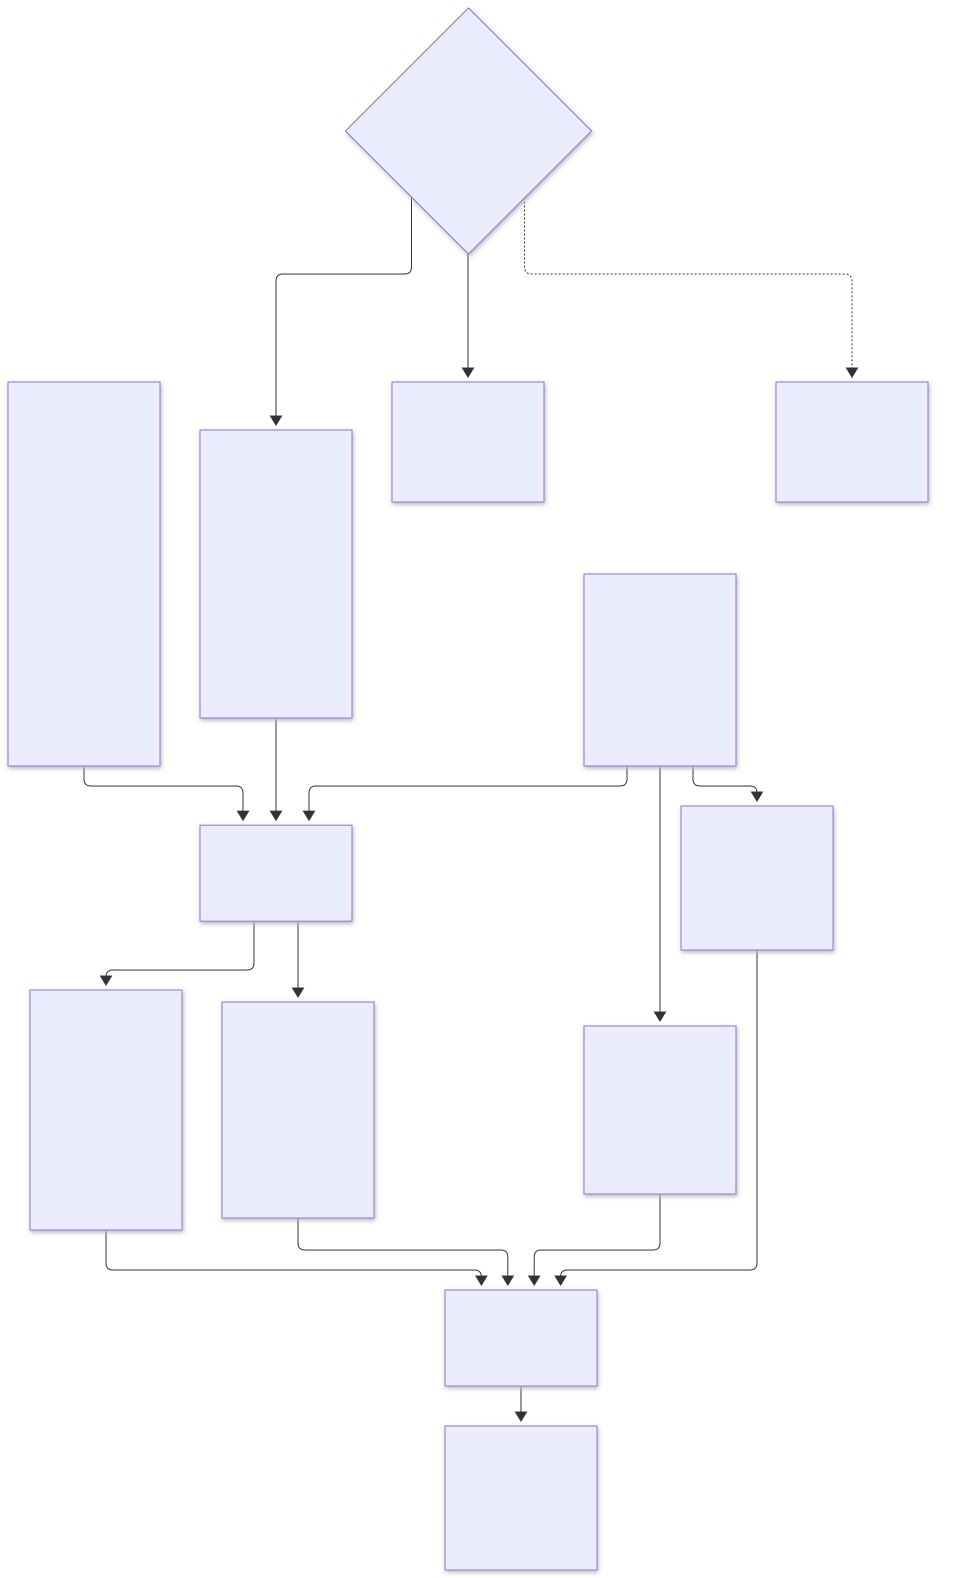

In [1]:
from IPython.display import SVG

from health_pricing import diagrams

SVG(filename=str(diagrams.svg_path("5a")))

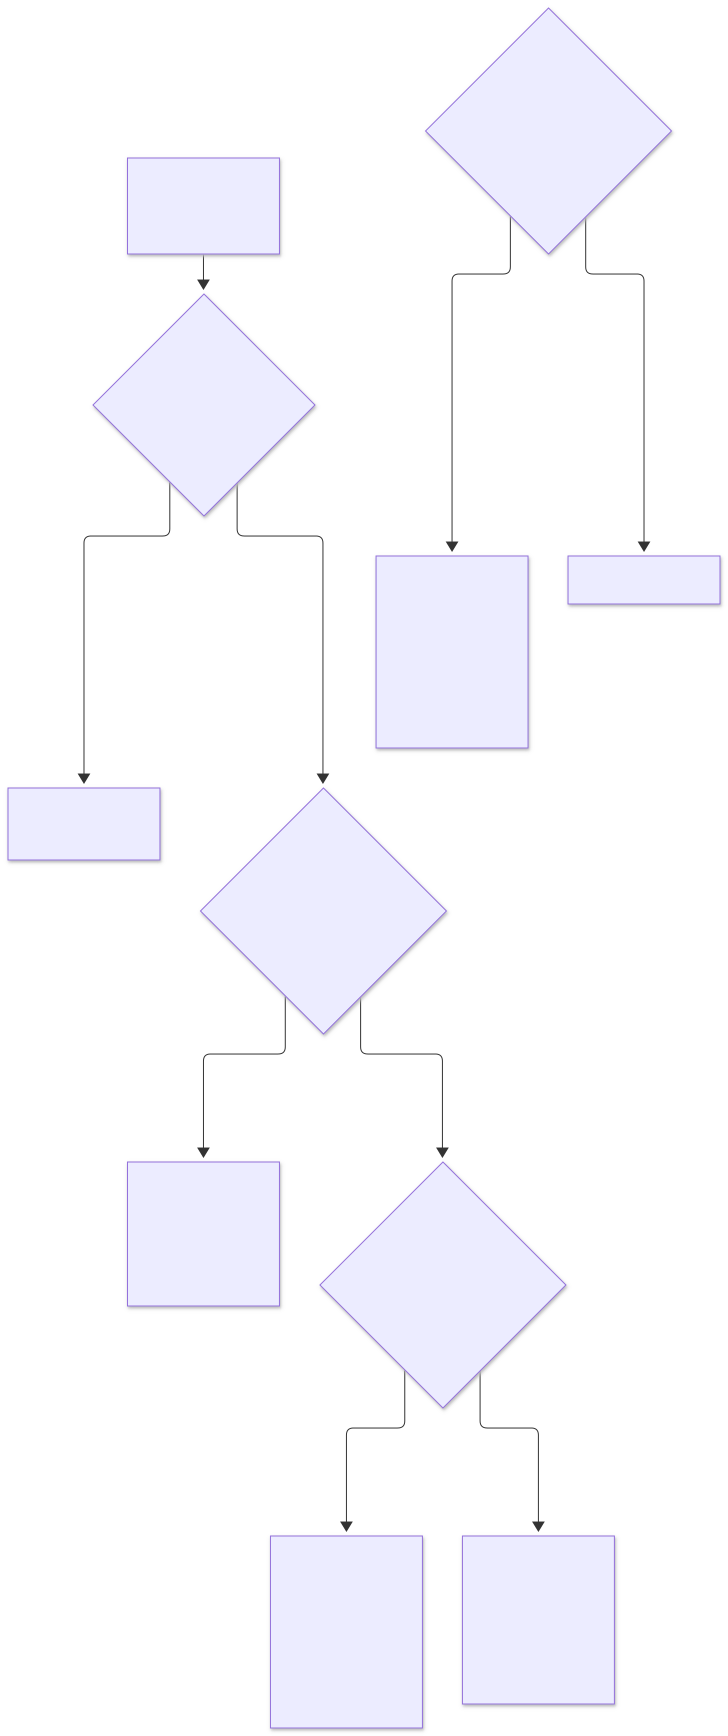

In [2]:
SVG(filename=str(diagrams.svg_path("5b")))

## Frozen model and the 2023 scoring frame

In [3]:
import pandas as pd

from health_pricing.models import glm, outofsample

pd.options.display.float_format = "{:,.3f}".format
frozen = outofsample.freeze()
oot = outofsample.load_out_of_time(frozen)
pd.DataFrame(
    {
        "model": [outofsample.TECHNICAL, outofsample.TARIFF],
        "parameters": [
            frozen.spline.model.parameters,
            frozen.final_tariff.tariff.parameters,
        ],
        "rebalancing_factor": [frozen.balance, 1.0],
    }
)

,model,parameters,rebalancing_factor
0,(a) Technical model,64,1.116
1,(a) Tariff,26,1.000


### 2023 next to 2022

The table puts 2023 next to 2022 train and test. Cost per exposure year is on the 2023 price basis. The last columns show the
cost above the large-claim cap of 100,000 dollars per person-year, which the provisional 6.5 percent load covers.

In [4]:
period_summary = outofsample.period_summary(frozen, oot)
outofsample.save_table(period_summary, "period_summary.csv")
period_summary

,period,person_years,exposure,claimants,claimant_rate,cost_per_exposure_year,mean_cost_per_claimant,claimants_above_cap,share_of_cost_above_cap,excess_load,cost_per_exposure_year_vs_2022_train
0,2022 train,17596,"17,440.750",7195,0.409,"2,183.395","5,292.570",32,0.061,0.065,0.000
1,2022 test,4151,"4,100.333",1725,0.416,"2,377.607","5,651.584",11,0.108,0.121,0.089
2,2023,18463,"18,301.250",7763,0.420,"2,551.995","6,016.320",46,0.058,0.062,0.169


The 2023 rows have 18,463 person-years and 18,301 years of exposure. Cost per exposure year is 2,552 dollars, which is 16.9
percent above 2022 train (2,183) and 7.3 percent above 2022 test (2,378). The claimant rate is 42.0 percent against 40.9
percent in train and 41.6 percent in test, and the mean cost per claimant is 6,016 dollars against 5,293 in train. So both
more people claim and each claim costs more, and the next section sorts out how much of each is the model's mix and how much
is a change in level. A total of 46 person-years in 2023 are above the cap, and the excess is 6.2 percent of capped cost,
against the provisional load of 6.5 percent.

### Levels that are new in 2023

Every 2023 level of every factor is mapped to a group with the M3 grouping. A level that the grouping had not seen would be
treated as the reference group and listed here.

In [5]:
outofsample.save_table(oot.new_levels, "new_levels_2023.csv")
print(f"Levels new in 2023: {len(oot.new_levels)}")
oot.new_levels

Levels new in 2023: 0


,factor,level,rows,treated_as


No level in 2023 is new to the grouping, so no row is moved to a reference group.

### The frozen model reproduces the GLM notebook

The technical model and the tariff are rebuilt from the 2022 train split. Their scores on train and test should equal those
saved by the GLM notebook (a test checks this to rounding).

In [6]:
scores = pd.concat(
    [
        glm.candidate_scores(
            name,
            parameters,
            {
                "train": (frozen.prepared.train, predictor(frame_train)),
                "test": (frozen.prepared.test, predictor(frame_test)),
            },
        )
        for name, parameters, predictor, frame_train, frame_test in (
            (
                outofsample.TECHNICAL,
                frozen.spline.model.parameters,
                frozen.technical,
                frozen.final_tariff.frames["spline"].train,
                frozen.final_tariff.frames["spline"].test,
            ),
            (
                outofsample.TARIFF,
                frozen.final_tariff.tariff.parameters,
                frozen.tariff,
                frozen.prepared.train,
                frozen.prepared.test,
            ),
        )
    ],
    ignore_index=True,
)
outofsample.save_table(scores.drop(columns="dropped_reason"), "frozen_model_scores_2022.csv")
scores

,candidate,split,tweedie_deviance,mean_tweedie_deviance,tweedie_deviance_p1_3,tweedie_deviance_p1_7,gini,a_e,parameters,dropped_reason
0,(a) Technical model,train,"3,031,554.108",172.287,"12,879,619.363","887,948.424",0.492,1.000,64,
1,(a) Technical model,test,"831,786.305",200.382,"3,671,617.500","231,890.463",0.386,1.081,64,
2,(a) Tariff,train,"3,051,674.804",173.430,"12,968,757.123","892,816.020",0.488,1.000,26,
3,(a) Tariff,test,"838,173.103",201.921,"3,700,064.950","233,355.176",0.378,1.081,26,


The technical model has a test deviance of 831,786 and a Gini of 0.386, and the tariff has 838,173 and 0.378. Both equal the
values saved by the GLM notebook. On train, predicted cost equals actual cost by construction (A/E of 1.000), and on the test
split A/E is 1.081.

## Frequency trend and the forecast assumption (decided)

Between 2022 and 2023 cost per exposure year rose 16.9 percent after on-levelling. To predict 2023 from the 2022 model, a
forecast trend has to be assumed, and **it was set without looking at 2023**. The options were the following.

1. **None (0 percent).** The 2022 model is used as it is. It is kept as a sensitivity.
2. **An external forecast made before 2023.** The median utilization trend for 2022 to 2023 that US insurers assumed in their plan
   year 2023 filings, from Worksheet I of the CMS Unified Rate Review public use file, weighted by member months, for inpatient and
   outpatient care. The source, its vintage and the value are recorded below. This is the **central forecast**, with the lower and
   upper quartiles as the sensitivity range.
3. **The trend that the data imply.** The 2022 to 2023 change in claim frequency measured on the same data. This is a
   **diagnostic only**. It is reported as the trend the data imply and is not used as a forecast assumption, because setting the trend from 2023 would make the frequency part of the 2023 A/E close to 1 by construction, and the out-of-time test would then test less than it should.

**How the trend is applied.** The decision is to apply the forecast as a utilization trend on **expected annual cost**, so each
prediction is multiplied by the factor (expected cost × 1.019). The reason is that the URR utilization trend is services per member,
and in this structure most extra use shows up as more claims per claimant. Claims per exposure year rose 9.3 percent while the share
of person-years with a claim rose 2.7 percent, so a trend on the claim hazard alone would leave out most of the use. The hazard-only
application, $1 - (1 - p)^f$ on the technical model with the tariff carrying its average rise, is shown alongside for comparison.

In [7]:
from health_pricing.data import urr
from health_pricing.models import figures, trend

external = urr.utilization_trends(urr.read_worksheet1())
outofsample.save_table(external, "external_trend_urr.csv")
external

,market,category,filings,member_months,p25,p50,p75
0,all,inpatient,713,"275,525,046.000",0.997,1.015,1.030
1,all,outpatient,713,"275,525,046.000",1.016,1.025,1.034
2,all,blend,713,"275,525,046.000",1.008,1.019,1.031
3,individual,inpatient,285,"159,100,806.000",1.000,1.016,1.030
4,individual,outpatient,285,"159,100,806.000",1.015,1.025,1.030
5,individual,blend,285,"159,100,806.000",1.008,1.018,1.030
6,small group,inpatient,428,"116,424,240.000",0.993,1.013,1.032
7,small group,outpatient,428,"116,424,240.000",1.020,1.029,1.039
8,small group,blend,428,"116,424,240.000",1.008,1.023,1.032


### The external figure

**Source.** CMS Unified Rate Review public use file for plan year 2023, Worksheet I (file `PY2023_WKSH1_PUF_20221027.csv`, in the
archive `2023-urr-puf.zip` that CMS last updated on 1 November 2022, downloaded from `www.cms.gov/files/zip/2023-urr-puf.zip`
with its size and checksum verified). **Vintage.** The filings were made in 2022 for coverage from 2023, so the figure was
available before 2023. **Selection.** Filings with a calendar-year 2021 experience period and a projection starting on 1 January
2023, for which the Year 2 trend runs from 2022 to 2023. Filings with no member months or no entered trend are left out. Quartiles
are weighted by member months. **Value.** The median utilization trend is a rise of 1.5 percent for inpatient care and 2.5 percent
for outpatient care, and 1.9 percent when the two are blended by their shares of experience claims (quartiles 0.8 and 3.1 percent).
The table gives the figures for individual and small group filings separately.

**Limits of the figure.** It is the utilization trend that insurers assumed for the number of services per member, which is not the
same measure as the share of person-years with a claim. It is also an assumption made by US insurers, and it describes the
commercial market and not the whole population.

**Context only.** The CMS National Health Expenditure actuals for 2023, published in December 2024, show real health spending
growth of 4.4 percent in 2023 against 1.4 percent in 2022, with price growth low at 0.6 percent, so most of the growth came from the
use and intensity of services (Health Affairs, "National Health Expenditure Accounts for 2023", 18 December 2024). They were
published after 2023 and are used only to interpret the gap below. They are not a forecast input.

### Why cost per exposure year rose 16.9 percent

The ratio of 2023 to 2022 train in cost per exposure year is split exactly into four parts, which multiply to the total. Intervals resample households within each period. The two periods are resampled independently, although many people and households are in both years, so the intervals of the ratios are somewhat wider than they need to be.

- **Mix** is the change in the cost that the model expects from the people covered (the modelled factors).
- **Frequency** is the change in actual claimants over the model's expected claimants.
- **Severity beyond the price index** is the change in actual capped cost per claimant over the model's expected cost per claimant.
  The 2022 costs are already on 2023 prices, so the price index is not counted twice. It is read as mainly **intensity**, meaning more services per claimant and a different mix of services, because the price index has already been removed. On the figures below, claims per claimant rose by about 6 percent and cost per claim by about 7 percent. This is an inference from claims per exposure year and the claimant rate, whose intervals overlap, and part of the severity change is sampling noise.
- **Large claims** is the change in the share of cost above the cap.

"Frequency" counts person-years with a claim, so the number of services each claimant uses is in the severity part.

In [8]:
train_pieces = trend.train_parts(frozen)
later_pieces = trend.out_of_time_parts(frozen, oot)
gap = trend.decomposition(train_pieces, later_pieces)
outofsample.save_table(gap, "gap_decomposition.csv")
gap

,component,ratio,change_percent,lower_95_percent,upper_95_percent,share_of_log_gap,pricing_treatment
0,Mix of people (modelled factors),1.001,0.147,-2.083,2.423,0.009,Not a level change. The rating structure price...
1,Frequency (actual over expected claimants),1.027,2.733,0.210,5.330,0.173,A level change if it persists. It is a trend o...
2,Severity beyond the price index,1.139,13.934,5.595,22.981,0.836,A level change if it persists. It is a trend o...
3,Large-claim contribution,0.997,-0.289,-4.474,3.786,-0.019,Not a level change. The large-claim load cover...
4,"Total, cost per exposure year",1.169,16.882,5.911,29.342,1.000,The total gap. The level change is frequency a...


Cost per exposure year rose 16.9 percent (interval 5.9 to 29.3 percent). Severity beyond the price index is the largest part, at
13.9 percent (5.6 to 23.0), which is 84 percent of the gap on the log scale. Frequency rose 2.7 percent (0.2 to 5.3). The mix of
people moved by 0.1 percent (-2.1 to 2.4) and large claims by -0.3 percent (-4.5 to 3.8), so neither explains the gap.

**Reading the severity part.** It is read as mainly intensity, more services per claimant, because the price index is already removed. The split between more claims per claimant (about 6 percent) and a higher cost per claim (about 7 percent) is an inference, because the intervals of the claimant rate and of claims per exposure year overlap. That
is consistent with the CMS National Health Expenditure finding that growth in 2023 was driven by the use and intensity of services
with low price growth (0.6 percent). In this structure the extra use appears at least partly as more claims per claimant. **The size is not to be
taken at face value.** The MEPS magnitude of 13.9 percent (5.6 to 23.0) is well above the national real growth of 4.4 percent, which
means that it is noisy. The direction supports a level change, but the number does not.

**What a pricing team would treat as a level change.** Frequency and severity beyond the price index are changes in the cost of the
same people, so a pricing team would treat them as a trend on the base rate if they persist. The mix of people is not a level change,
because the rating structure already prices it. The large-claim contribution is not a level change either, because the load covers
it and the load is re-estimated separately. This is a single pair of years, so persistence is not shown. The recalibration rule
should therefore weight one year of noisy experience by its credibility and not recalibrate fully.

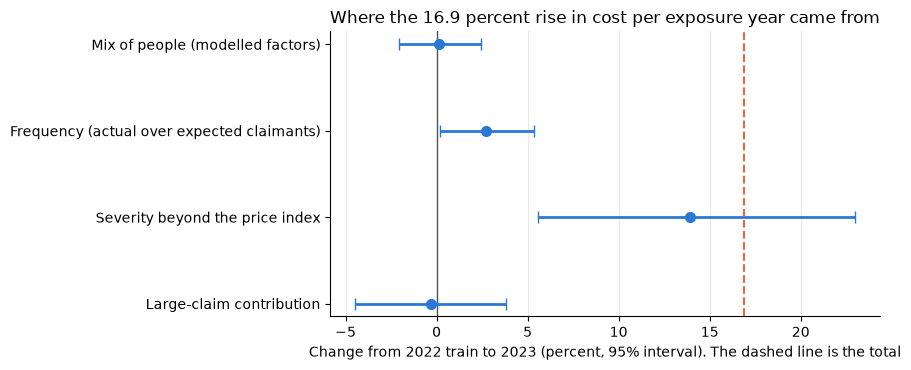

In [9]:
import matplotlib.pyplot as plt

shown = gap.iloc[:4]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvline(0, color="#52514e", linewidth=1)
positions = range(len(shown))
ax.errorbar(
    shown["change_percent"],
    positions,
    xerr=[
        shown["change_percent"] - shown["lower_95_percent"],
        shown["upper_95_percent"] - shown["change_percent"],
    ],
    fmt="o",
    markersize=7,
    capsize=4,
    linewidth=2,
    color="#2a78d6",
)
ax.set_yticks(list(positions), shown["component"])
ax.invert_yaxis()
ax.axvline(gap["change_percent"].iloc[4], color="#eb6834", linestyle="--", linewidth=1.5)
ax.set_xlabel(
    "Change from 2022 train to 2023 (percent, 95% interval). The dashed line is the total"
)
ax.set_title("Where the 16.9 percent rise in cost per exposure year came from")
ax.grid(axis="x", color="#e8e8e6", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
figures.save_figure(fig, "gap_decomposition", outofsample.OUTPUT_DIR / "figures")
plt.show()

### Frequency by age group

The table shows the share of person-years with a claim and claims per exposure year in 2022 and 2023, for all person-years and for
children and three adult age groups, with the ratio of 2023 to 2022 train and a household interval. The actual-over-expected
columns adjust for the mix of people, because the expected claimants come from the model.

In [10]:
frequency = trend.frequency_table(frozen, oot)
outofsample.save_table(frequency, "frequency_by_age_group.csv")
frequency[
    [
        "group",
        "period",
        "person_years",
        "claimant_rate",
        "claims_per_exposure_year",
        "claimant_rate_vs_2022_train",
        "claimant_rate_vs_2022_train_lower_95",
        "claimant_rate_vs_2022_train_upper_95",
        "actual_over_expected_vs_2022_train",
        "actual_over_expected_vs_2022_train_lower_95",
        "actual_over_expected_vs_2022_train_upper_95",
    ]
]

,group,period,person_years,claimant_rate,claims_per_exposure_year,claimant_rate_vs_2022_train,claimant_rate_vs_2022_train_lower_95,claimant_rate_vs_2022_train_upper_95,actual_over_expected_vs_2022_train,actual_over_expected_vs_2022_train_lower_95,actual_over_expected_vs_2022_train_upper_95
0,All,2022 train,17596,0.409,3.057,NaN,NaN,NaN,NaN,NaN,NaN
1,All,2022 test,4151,0.416,3.040,NaN,NaN,NaN,NaN,NaN,NaN
2,All,2023,18463,0.420,3.343,1.028,0.998,1.058,1.027,1.002,1.053
3,Children,2022 train,3387,0.184,1.045,NaN,NaN,NaN,NaN,NaN,NaN
4,Children,2022 test,787,0.188,1.544,NaN,NaN,NaN,NaN,NaN,NaN
5,Children,2023,3556,0.193,1.470,1.046,0.930,1.162,1.054,0.940,1.170
6,18-39,2022 train,4260,0.262,1.589,NaN,NaN,NaN,NaN,NaN,NaN
7,18-39,2022 test,968,0.269,1.740,NaN,NaN,NaN,NaN,NaN,NaN
8,18-39,2023,4425,0.281,1.858,1.076,0.999,1.156,1.075,1.003,1.154
9,40-64,2022 train,5684,0.455,3.280,NaN,NaN,NaN,NaN,NaN,NaN


The share of person-years with a claim rose 2.8 percent (-0.2 to 5.8) and the mix-adjusted figure rose 2.7 percent (0.2 to 5.3).
Claims per exposure year rose more, by 9.3 percent (2.4 to 16.3), so people who claim made more claims as well. By age group, the
share with a claim rose 4.6 percent for children (-7.0 to 16.2), 7.6 percent for ages 18 to 39 (-0.1 to 15.6), 2.1 percent for 65 and
over (-0.8 to 5.2) and did not move for ages 40 to 64 (-0.2, with an interval of -4.4 to 4.2). The mix-adjusted ratio for ages 18 to 39 is 1.075 (1.003 to 1.154), the only age group whose interval excludes 1. Claims per exposure year for children rose by 40.6 percent (3 to 89), which is the largest movement, but it is unstable, because 2022 train has 1.05 claims per exposure year and 2022 test has 1.54, so it is read as noise.

### The 2023 A/E under each trend option

The table gives the A/E of 2023 (actual cost over predicted cost) for the technical model and the tariff, with a household interval.
The central forecast, the sensitivity range and no trend are applied to expected annual cost. The hazard-only application of the
central trend is shown for comparison. The trend the data imply is the hazard factor that makes the model's expected claimants
match the claimants of 2023, given how well the model's frequency was calibrated on 2022 train. It is a diagnostic and not a
forecast.

In [11]:
central = external[(external["market"] == "all") & (external["category"] == "blend")].iloc[0]
implied = trend.implied_hazard_factor(train_pieces, later_pieces)
source = "CMS URR PUF plan year 2023, Worksheet I, Year 2 utilization, blend"
options = {
    "Central: URR median, +1.9 percent on expected cost": (
        central["p50"],
        trend.COST,
        source,
        "Central forecast",
    ),
    "Sensitivity: URR lower quartile, +0.8 percent on expected cost": (
        central["p25"],
        trend.COST,
        source,
        "Sensitivity range",
    ),
    "Sensitivity: URR upper quartile, +3.1 percent on expected cost": (
        central["p75"],
        trend.COST,
        source,
        "Sensitivity range",
    ),
    "Sensitivity: no trend, 0 percent": (1.0, trend.COST, "No trend", "Sensitivity"),
    "Comparison: URR median on the claim hazard only": (
        central["p50"],
        trend.HAZARD,
        source,
        "Comparison",
    ),
    "Diagnostic only: the trend the data imply, on the claim hazard": (
        implied,
        trend.HAZARD,
        "Implied by the 2022 to 2023 data",
        "Diagnostic only, not a forecast",
    ),
}
trend_table = trend.trend_options(frozen, oot, options)
outofsample.save_table(trend_table, "trend_options_ae.csv")
trend_table

,option,factor,trend_percent,applied_to,technical_a_e,technical_lower_95,technical_upper_95,tariff_a_e,tariff_lower_95,tariff_upper_95,source,use
0,"Central: URR median, +1.9 percent on expected ...",1.019,1.900,cost,1.145,1.075,1.220,1.145,1.074,1.220,"CMS URR PUF plan year 2023, Worksheet I, Year ...",Central forecast
1,"Sensitivity: URR lower quartile, +0.8 percent ...",1.008,0.826,cost,1.158,1.086,1.233,1.157,1.086,1.233,"CMS URR PUF plan year 2023, Worksheet I, Year ...",Sensitivity range
2,"Sensitivity: URR upper quartile, +3.1 percent ...",1.031,3.076,cost,1.132,1.062,1.206,1.132,1.062,1.206,"CMS URR PUF plan year 2023, Worksheet I, Year ...",Sensitivity range
3,"Sensitivity: no trend, 0 percent",1.000,0.000,cost,1.167,1.095,1.243,1.167,1.095,1.243,No trend,Sensitivity
4,Comparison: URR median on the claim hazard only,1.019,1.900,hazard,1.155,1.084,1.231,1.155,1.084,1.230,"CMS URR PUF plan year 2023, Worksheet I, Year ...",Comparison
5,"Diagnostic only: the trend the data imply, on ...",1.046,4.573,hazard,1.139,1.069,1.214,1.139,1.069,1.213,Implied by the 2022 to 2023 data,"Diagnostic only, not a forecast"


With no trend the technical model has an A/E of 1.167 on 2023 (interval 1.095 to 1.243), which means actual cost is 16.7 percent
above the prediction. With the central forecast (expected cost × 1.019) the A/E is 1.145 (1.075 to 1.220). It is 1.158 at the lower
quartile (0.8 percent) and 1.132 at the upper quartile (3.1 percent). The tariff gives the same A/E to three decimals. So after the
central forecast, actual cost is still 14.5 percent above the prediction, and the interval does not include 1, even at the upper
quartile.

Applying the central trend to the claim hazard only gives an A/E of 1.155 (1.084 to 1.231), which is one point higher than applying
it to expected cost. A hazard-only trend lifts cost by about 1.0 percent, because the chance of a claim cannot rise by the full
factor for people who are already likely to claim, so it carries less of the use than a trend on cost. The trend that the data imply
(a hazard factor of 1.046) is a diagnostic and is not used as a forecast. It would leave an A/E of 1.139 (1.069 to 1.214).

The forecast choice moves the A/E by 2.2 points between no trend and the central forecast and by 3.5 points at the upper quartile,
which is far smaller than the gap and smaller than the width of the interval. The conclusion does not depend on it.

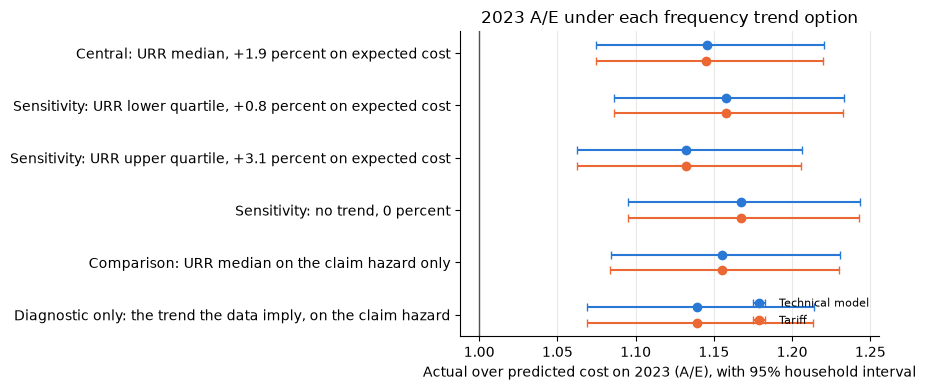

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvline(1.0, color="#52514e", linewidth=1)
labels = list(trend_table["option"])
for offset, model, colour, name in (
    (-0.15, "technical", "#2a78d6", "Technical model"),
    (0.15, "tariff", "#eb6834", "Tariff"),
):
    ax.errorbar(
        trend_table[f"{model}_a_e"],
        [k + offset for k in range(len(labels))],
        xerr=[
            trend_table[f"{model}_a_e"] - trend_table[f"{model}_lower_95"],
            trend_table[f"{model}_upper_95"] - trend_table[f"{model}_a_e"],
        ],
        fmt="o",
        markersize=6,
        capsize=3,
        linewidth=1.5,
        color=colour,
        label=name,
    )
ax.set_yticks(range(len(labels)), labels)
ax.invert_yaxis()
ax.set_xlabel("Actual over predicted cost on 2023 (A/E), with 95% household interval")
ax.set_title("2023 A/E under each frequency trend option")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="x", color="#e8e8e6", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
figures.save_figure(fig, "ae_by_trend_option", outofsample.OUTPUT_DIR / "figures")
plt.show()

### How much of the gap is the large-claim load

The provisional load of 6.5 percent comes from 2022 train. The cost above the cap in 2023 is 6.2 percent of capped cost. The table
shows how much the A/E would change if the load matched the 2023 excess. Nothing is tuned for it, and the load is re-estimated later.

In [13]:
own_load = oot.frame["cost"].sum() / oot.frame["capped_cost"].sum() - 1
load = trend.load_check(frozen, later_pieces, float(own_load))
outofsample.save_table(pd.DataFrame([load]), "load_check_2023.csv")
pd.DataFrame([load])

,a_e_provisional_load,own_excess_load,provisional_load,a_e_if_load_matched,change_in_a_e_points
0,1.167,0.062,0.065,1.171,0.369


The provisional load is already above the cost over the cap that 2023 shows (6.5 against 6.2 percent), so none of the A/E gap is
consistent with it. With a load that matched 2023 the A/E would be 1.171, which is 0.4 points higher. The load is not tuned and it
is re-estimated later.

### The A/E as a product of its parts

Both models are balanced on 2022 train, so their A/E on train is 1. The A/E of the technical model on 2023 is therefore the product
of the frequency, severity and large-claim ratios of 2023 to train, and the mix of people cancels out.

In [14]:
components = trend.ae_components(frozen, oot, train_pieces, later_pieces)
outofsample.save_table(components, "ae_components_2023.csv")
components

,measure,value,lower_95,upper_95
0,Technical model A/E,1.167,1.095,1.243
1,Tariff A/E,1.167,1.095,1.243
2,Frequency (actual over expected claimants),1.027,1.002,1.053
3,Severity beyond the price index,1.139,1.056,1.230
4,Large-claim contribution,0.997,0.955,1.038


### Decision on the forecast trend (decision gate 4, part 2)

**Decided.** The central forecast is the median utilization trend of the CMS Unified Rate Review filings for plan year 2023,
**1.9 percent**, with **0.8 and 3.1 percent** (the lower and upper quartiles) as the sensitivity range. It is applied as a utilization
trend on expected annual cost, so expected cost × 1.019, with the hazard-only application shown alongside and no trend (0 percent)
as a further sensitivity. The trend that the data imply is never used as a forecast.

**Source, vintage and value.** CMS Unified Rate Review public use file for plan year 2023, Worksheet I, file
`PY2023_WKSH1_PUF_20221027.csv` in `2023-urr-puf.zip` (CMS update of 1 November 2022). The filings were made in 2022. There are 713
filings with a calendar-year 2021 experience period and a projection from 1 January 2023, with 275.5 million member months, and
the Year 2 trend runs from 2022 to 2023. The member-month weighted median is 1.5 percent for inpatient care, 2.5 percent for outpatient
care and 1.9 percent blended by the share of experience claims, with quartiles of 0.8 and 3.1 percent.

**For the recalibration rule.** The 2023 evidence points to a level change, but it is one year of noisy experience, so the
recalibration rule weights it by its credibility and does not recalibrate fully.

## A/E on 2023 with the forecast trend

The technical model and the tariff are scored on the 2023 rows with the decided forecast, which multiplies expected annual cost by
1.019. The yardstick is the one of the GLM notebook. Intervals come from resampling households with a fixed seed. The A/E is the
actual cost over the predicted cost, so a value above 1 means the model under-predicted.

In [15]:
from health_pricing.models import monitoring

forecast_factor = float(central["p50"])
predictions = monitoring.forecast(frozen, oot, forecast_factor)
overall_ae = monitoring.overall(oot, predictions)
outofsample.save_table(overall_ae, "ae_overall_2023.csv")
overall_ae

,model,actual,expected,a_e,lower_95,upper_95,relative_a_e,relative_lower_95,relative_upper_95
0,(a) Technical model,"46,704,693.500","40,778,113.372",1.145,1.075,1.220,1.000,1.000,1.000
1,(a) Tariff,"46,704,693.500","40,780,643.339",1.145,1.074,1.220,1.000,1.000,1.000


With the central forecast, the technical model and the tariff both have an A/E of 1.145 on 2023 (interval 1.075 to 1.220), so actual
cost is 14.5 percent above the prediction and the interval does not include 1. The two models agree to three decimals, because the
tariff is an approximation to the technical model. Most of this is the level shift that the previous section decomposed, and the
part that no forecast trend removes is the severity beyond the price index. The provisional large-claim load is not the source of
the gap, because it is already higher than the cost over the cap that 2023 shows (6.5 against 6.2 percent). Nothing is tuned for it.

### Ranking and deviance on 2023

The deviance of each model is shown at three Tweedie powers, with the Gini and the A/E. The baseline predicts the 2022 train cost
per exposure year for everyone, so it does not rank anyone and its Gini is 0. The reduction is against that baseline.

In [16]:
scores_2023 = monitoring.scores(frozen, oot, predictions)
outofsample.save_table(scores_2023, "scores_2023.csv")
scores_2023

,candidate,tweedie_deviance,mean_tweedie_deviance,tweedie_deviance_p1_3,tweedie_deviance_p1_7,gini,a_e,deviance_reduction_pct
0,Baseline (2022 train mean),"4,196,352.667",227.284,"18,614,826.745","1,135,610.100",0.000,1.169,0.000
1,(a) Technical model,"3,506,652.712",189.929,"15,360,284.480","988,352.417",0.473,1.145,16.436
2,(a) Tariff,"3,539,069.152",191.684,"15,499,557.704","996,209.013",0.468,1.145,15.663


The ranking survives the move to 2023. The technical model has a Gini of 0.473 and a deviance 16.4 percent below the baseline, and
the tariff has a Gini of 0.468 and a deviance 15.7 percent below it. The baseline has an A/E of 1.169 because it uses the 2022 cost
per exposure year, and its Gini is 0. The gap between the tariff and the technical model is small (0.006 of Gini and 0.8 points of
deviance reduction), so the price of a multiplicative tariff stays small out of time. The Gini on 2023 is higher than on the 2022
test split (0.386), which is a different and smaller sample, so it shows that the ranking has not been lost and it is not evidence
of improvement. The deviance is at the 1.5 power, and the 1.3 and 1.7 columns give the same ordering.

### A/E by age group

In [17]:
age_ae = monitoring.by_age_group(oot, predictions)
outofsample.save_table(age_ae, "ae_by_age_group_2023.csv")
age_ae

,model,age_group,actual,expected,a_e,lower_95,upper_95,relative_a_e,relative_lower_95,relative_upper_95
7,(a) Tariff,Children,"2,369,828.870","2,096,638.639",1.130,0.882,1.423,0.987,0.776,1.235
4,(a) Tariff,18-39,"5,076,986.310","4,927,503.277",1.030,0.862,1.229,0.900,0.759,1.068
5,(a) Tariff,40-64,"16,615,741.200","14,799,804.942",1.123,1.007,1.255,0.980,0.900,1.066
6,(a) Tariff,65+,"22,642,137.120","18,956,696.481",1.194,1.092,1.308,1.043,0.975,1.110
3,(a) Technical model,Children,"2,369,828.870","2,090,903.248",1.133,0.883,1.426,0.990,0.777,1.238
0,(a) Technical model,18-39,"5,076,986.310","4,929,688.152",1.030,0.862,1.227,0.899,0.758,1.067
1,(a) Technical model,40-64,"16,615,741.200","14,787,209.716",1.124,1.008,1.255,0.981,0.901,1.068
2,(a) Technical model,65+,"22,642,137.120","18,970,312.255",1.194,1.090,1.306,1.042,0.975,1.109


The A/E by age group is 1.13 for children (0.88 to 1.42), 1.03 for ages 18 to 39 (0.86 to 1.23), 1.12 for ages 40 to 64 (1.01 to 1.26)
and 1.19 for ages 65 and over (1.09 to 1.31), the same for both models to the second decimal. The groups differ by less than their intervals, and every interval contains the overall A/E of 1.145. The relative A/E, the group over the overall, is 0.90 to 1.04, so the shift in level is spread across the age groups. The age structure is not contradicted, but ages 65 and over (1.19) against ages 18 to 39 (1.03) is a gap of 16 percent, and the intervals are too wide to confirm or reject it.

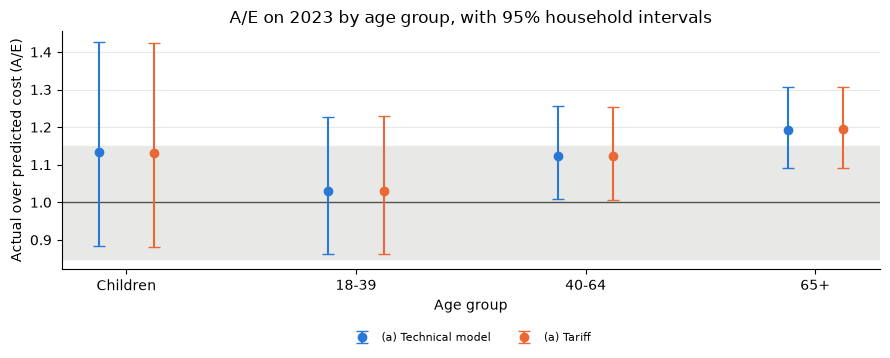

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axhline(1.0, color="#52514e", linewidth=1)
ax.axhspan(0.85, 1.15, color="#e8e8e6", zorder=0)
for offset, name, colour in (
    (-0.12, outofsample.TECHNICAL, "#2a78d6"),
    (0.12, outofsample.TARIFF, "#eb6834"),
):
    part = age_ae[age_ae["model"] == name].reset_index(drop=True)
    ax.errorbar(
        [k + offset for k in range(len(part))],
        part["a_e"],
        yerr=[part["a_e"] - part["lower_95"], part["upper_95"] - part["a_e"]],
        fmt="o",
        markersize=6,
        capsize=4,
        linewidth=1.5,
        color=colour,
        label=name,
    )
ax.set_xticks(range(len(part)), part["age_group"])
ax.set_xlabel("Age group")
ax.set_ylabel("Actual over predicted cost (A/E)")
ax.set_title("A/E on 2023 by age group, with 95% household intervals")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
figures.save_figure(fig, "ae_by_age_group_2023", outofsample.OUTPUT_DIR / "figures")
plt.show()

### A/E by factor level

For every level of every factor, the A/E is shown with a household interval. A level is flagged when it has at least 30 claimants and
an A/E outside 0.85 to 1.15. The overall A/E is already above 1.1, so the **relative A/E** (the level's A/E over the overall A/E) is
also shown. It separates a difference in the structure from the level shift that affects every level. A level whose relative interval
contains 1 moves with the whole book. The analysis-only factors are shown for information.

In [19]:
levels_2023 = pd.concat(
    {name: monitoring.by_level(oot, predicted) for name, predicted in predictions.items()},
    names=["model"],
).reset_index(level=0)
levels_2023["outside_and_off_the_book"] = (
    levels_2023["outside_band"] & ~levels_2023["moves_with_the_book"]
)
summary_levels = (
    levels_2023[levels_2023["enough_claimants"]]
    .groupby(["model", "role"])
    .agg(
        levels_checked=("a_e", "size"),
        outside_band=("outside_band", "sum"),
        outside_band_and_off_the_book=("outside_and_off_the_book", "sum"),
    )
    .reset_index()
)
outofsample.save_table(levels_2023, "ae_by_level_2023.csv")
summary_levels

,model,role,levels_checked,outside_band,outside_band_and_off_the_book
0,(a) Tariff,analysis_only,20,12,9
1,(a) Tariff,dropped,8,4,3
2,(a) Tariff,rating,34,15,2
3,(a) Technical model,analysis_only,20,12,9
4,(a) Technical model,dropped,8,4,3
5,(a) Technical model,rating,34,15,2


In [20]:
flagged_levels = monitoring.flagged(levels_2023[levels_2023["model"] == outofsample.TARIFF])
flagged_levels[flagged_levels["role"] == "rating"][
    [
        "factor",
        "level",
        "claimants",
        "a_e",
        "lower_95",
        "upper_95",
        "relative_a_e",
        "relative_lower_95",
        "relative_upper_95",
        "moves_with_the_book",
    ]
]

,factor,level,claimants,a_e,lower_95,upper_95,relative_a_e,relative_lower_95,relative_upper_95,moves_with_the_book
0,ARTHDX,1,3117,1.190,1.093,1.300,1.039,0.979,1.099,True
1,ASTHDX,0,6458,1.173,1.094,1.257,1.025,0.995,1.052,True
2,CANCERDX,1,1571,1.239,1.090,1.393,1.082,0.974,1.191,True
3,CHDDX,1,672,1.327,1.127,1.545,1.158,0.991,1.334,True
4,CHOLDX,1,3444,1.210,1.107,1.323,1.057,0.991,1.122,True
5,HIBPDX,1,3510,1.255,1.148,1.375,1.096,1.037,1.155,False
6,OHRTDX,1,1327,1.424,1.251,1.612,1.243,1.109,1.375,False
7,age,05-14,392,1.237,0.901,1.635,1.080,0.785,1.420,True
8,age,18-24,260,1.192,0.783,1.736,1.041,0.684,1.526,True
9,age,50-54,508,1.181,0.872,1.582,1.031,0.770,1.347,True


For the tariff, 15 of the 34 rating-factor levels with at least 30 claimants are outside 0.85 to 1.15, and the tariff and the
technical model give the same count. That is expected when the overall A/E is 1.145, because most levels sit above 1. The relative
A/E shows which levels differ from the overall level by more than sampling noise. Four rating levels do, which are the two levels of
high blood pressure and the two of other heart disease. Of these, two are also outside the band: high blood pressure present (A/E 1.25,
relative 1.10 with an interval of 1.04 to 1.16) and other heart disease present (A/E 1.42, relative 1.24 with an interval of 1.11 to
1.38). The other 13 levels outside the band move with the whole book. Four of 34 is more than the 1.7 that chance would give.

**A pattern in the conditions.** For every condition except asthma, the people who have it are under-predicted by more than the book
as a whole. The relative A/E is 1.10 for high blood pressure, 1.16 for coronary heart disease, 1.24 for other heart disease, 1.06 for
cholesterol, 1.08 for cancer and 1.04 for arthritis, and three of the four conditions that were dropped from the rating factors show the same direction (1.26 for heart attack, 1.33 for stroke and 1.21 for diabetes, each with an interval that excludes 1, while angina is 1.09 with an interval that includes 1). Only some of these
are clear one by one, but the direction is the same for nearly all of them. It is consistent with a morbidity structure that is too
low for 2023, which would also fit extra use being concentrated in people with conditions. It is one year of data, so it is a pattern
to watch and not a finding. Among the analysis-only factors, 12 of 20 levels are outside the band, and 4 of 8 for the factors that
were dropped. These are not priced, so their A/E reflects their real effect on top of the level shift, as in 2022.

**Reading.** Most of the A/E gap is a level shift that every level shares. The condition pattern is the one sign in these tables that
the structure may also have moved. The age structure and the lift below do not show one.

### Lift with household bands

Person-years are grouped by predicted cost per exposure year, in ten groups and in five, and the A/E of each group is shown with a
95 percent household band. The ten-group table is the A/E by predicted-cost decile.

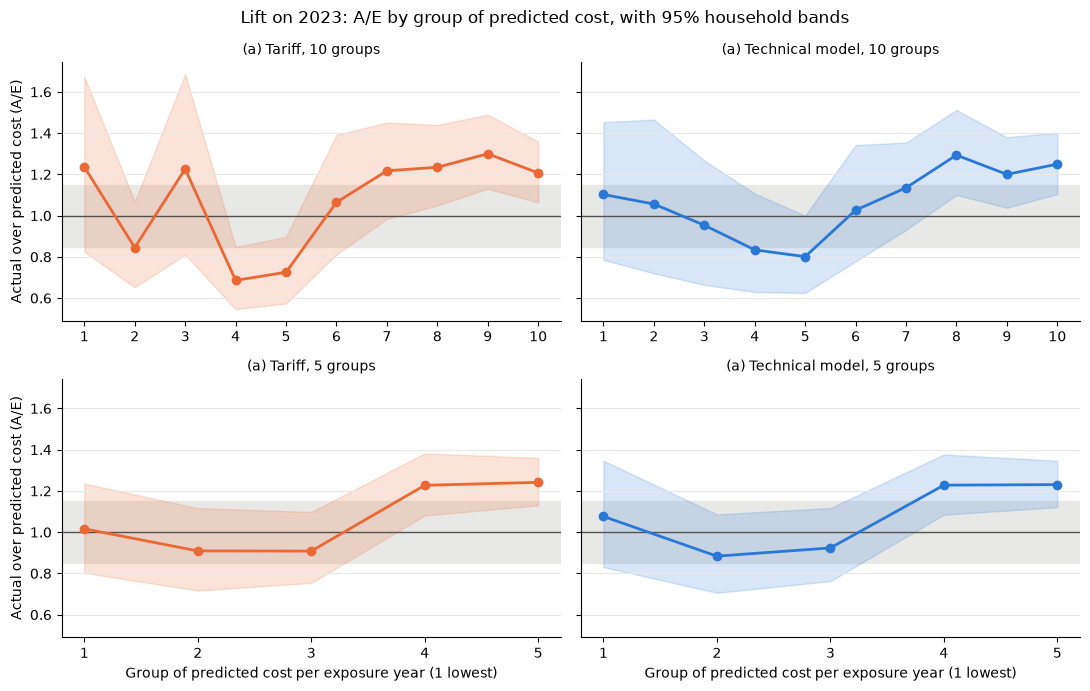

,model,group,person_years,a_e,lower_95,upper_95
0,(a) Technical model,1,1831,1.102,0.785,1.454
1,(a) Technical model,2,1870,1.056,0.720,1.465
2,(a) Technical model,3,1862,0.953,0.664,1.267
3,(a) Technical model,4,1834,0.834,0.630,1.107
4,(a) Technical model,5,1831,0.801,0.625,1.000
5,(a) Technical model,6,1836,1.026,0.778,1.342
6,(a) Technical model,7,1852,1.135,0.931,1.354
7,(a) Technical model,8,1845,1.293,1.100,1.512
8,(a) Technical model,9,1836,1.200,1.038,1.380
9,(a) Technical model,10,1866,1.249,1.105,1.402


In [21]:
lift_2023 = monitoring.lift(oot, predictions)
outofsample.save_table(lift_2023, "lift_by_group_2023.csv")
outofsample.save_table(
    lift_2023[lift_2023["groups"] == 10].drop(columns="groups"), "ae_by_decile_2023.csv"
)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for row, groups in enumerate((10, 5)):
    for column, (name, colour) in enumerate(
        ((outofsample.TARIFF, "#eb6834"), (outofsample.TECHNICAL, "#2a78d6"))
    ):
        ax = axes[row, column]
        shown = lift_2023[(lift_2023["model"] == name) & (lift_2023["groups"] == groups)]
        ax.axhspan(0.85, 1.15, color="#e8e8e6", zorder=0)
        ax.axhline(1.0, color="#52514e", linewidth=1)
        ax.fill_between(
            shown["group"], shown["lower_95"], shown["upper_95"], color=colour, alpha=0.18
        )
        ax.plot(shown["group"], shown["a_e"], color=colour, marker="o", markersize=6, linewidth=2)
        ax.set_xticks(range(1, groups + 1))
        ax.set_title(f"{name}, {groups} groups", fontsize=10)
        ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel("Group of predicted cost per exposure year (1 lowest)")
for ax in axes[:, 0]:
    ax.set_ylabel("Actual over predicted cost (A/E)")
fig.suptitle("Lift on 2023: A/E by group of predicted cost, with 95% household bands")
plt.tight_layout()
figures.save_figure(fig, "lift_2023", outofsample.OUTPUT_DIR / "figures")
plt.show()
lift_2023[lift_2023["groups"] == 10][
    ["model", "group", "person_years", "a_e", "lower_95", "upper_95"]
]

The lift is noisy, as for any 18,463 person-years with a heavy tail, and it shows no steady slope across the groups. For the technical model
the A/E is 1.10 in the lowest decile, falls to 0.80 to 0.83 in deciles 4 and 5, and rises to 1.20 to 1.29 in deciles 8 to 10. For the
tariff the deciles 4 and 5 are 0.69 and 0.73, and their bands (0.55 to 0.85 and 0.57 to 0.90) exclude 1, and deciles 8 to 10 are 1.21 to
1.30. The top deciles are under-predicted, which is the opposite of over-spreading, and it is the level shift acting on the largest
costs. The wide bands in the lowest deciles mean that nothing is
concluded from them.

### Double lift of the tariff against the technical model

Person-years are grouped by the ratio of the two predictions. The model that tracks actual cost better has an A/E nearer 1 across the
groups.

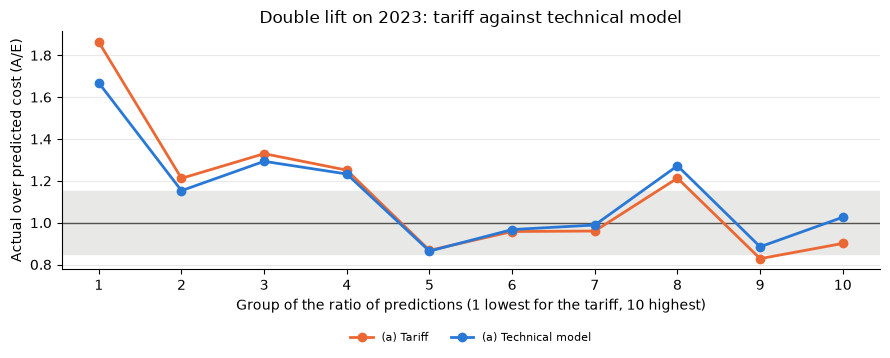

,group,exposure,actual,predicted (a) Tariff,predicted (a) Technical model,A/E (a) Tariff,A/E (a) Technical model
0,1,"1,829.667","7,721,749.330","4,145,045.931","4,628,839.069",1.863,1.668
1,2,"1,830.333","5,674,254.120","4,682,287.269","4,921,324.386",1.212,1.153
2,3,"1,830.250","7,090,907.890","5,332,173.680","5,483,253.491",1.330,1.293
3,4,"1,830.167","4,988,850.490","3,987,623.465","4,047,579.210",1.251,1.233
4,5,"1,830.250","3,708,096.400","4,273,784.018","4,291,601.015",0.868,0.864
5,6,"1,829.917","4,299,260.530","4,489,125.468","4,445,518.225",0.958,0.967
6,7,"1,830.167","4,196,253.910","4,370,823.729","4,243,715.281",0.960,0.989
7,8,"1,830.083","2,801,031.380","2,309,488.884","2,202,132.033",1.213,1.272
8,9,"1,829.917","2,877,293.930","3,474,942.626","3,252,049.359",0.828,0.885
9,10,"1,830.500","3,346,995.520","3,715,348.269","3,262,101.303",0.901,1.026


In [22]:
double_2023 = monitoring.double_lift(oot, predictions)
outofsample.save_table(double_2023, "double_lift_2023.csv")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axhline(1.0, color="#52514e", linewidth=1)
ax.axhspan(0.85, 1.15, color="#e8e8e6", zorder=0)
ax.plot(
    double_2023["group"],
    double_2023[f"A/E {outofsample.TARIFF}"],
    color="#eb6834",
    marker="o",
    markersize=6,
    linewidth=2,
    label=outofsample.TARIFF,
)
ax.plot(
    double_2023["group"],
    double_2023[f"A/E {outofsample.TECHNICAL}"],
    color="#2a78d6",
    marker="o",
    markersize=6,
    linewidth=2,
    label=outofsample.TECHNICAL,
)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Group of the ratio of predictions (1 lowest for the tariff, 10 highest)")
ax.set_ylabel("Actual over predicted cost (A/E)")
ax.set_title("Double lift on 2023: tariff against technical model")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.grid(axis="y", color="#e8e8e6", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
figures.save_figure(fig, "double_lift_2023", outofsample.OUTPUT_DIR / "figures")
plt.show()
double_2023

The technical model is nearer 1 than the tariff in 8 of the 10 groups, and the tariff is nearer in groups 5 and 8. The largest
difference is in the group where the tariff predicts lowest relative to the technical model (A/E 1.86 for the tariff against 1.67
for the technical model). The double lift carries no bands, so the differences are not tested, but they are modest and they are in the expected direction,
because the tariff is a multiplicative approximation to the technical model. Neither model is clearly better out of time.